# Impact of US macro releases on Bitcoin: a causal inference analysis
**Course** Causal Inference & Experimentation (MSA-DAT09-04) · **Final project** · Alexandro Bizeul, Julius Hayter, Léonard Schwob

> **Status.** Analysis run on **real data**: BTCUSDT 1-minute bars (Binance, 2022-01 to 2026-10), 151 releases
> (56 CPI and 57 NFP at 08:30 New York; 38 FOMC decisions at 14:00 New York), surprises = actual − consensus (NFP and *core* CPI, Investing.com) and
> Bauer-Swanson monetary policy surprises (FOMC 2022-2023). If the data files are missing, the notebook switches to
> **SIMULATED mode** (known true effect, no economic meaning).

| # | Project deliverable | Where |
|---|---|---|
| 1 | Causal question, estimands (potential outcomes) | §1 |
| 2 | DAG, backdoor criterion, what we control / do not control | §2 |
| 3 | Data, quality, calendar | §3 |
| 4 | **DiD** + parallel-trends test (event study), naive comparison | §5 |
| 5 | **Synthetic control** ("synthetic day", donor pool, placebos) | §6 |
| 6 | Directional effect (surprise) + robustness | §7 |
| 7 | Identification critique + **falsification** | §8–§10 |
| 8 | **One-page recommendation** | §11 |


## 0. Running the notebook
The notebook runs as is locally (from `notebooks/` or the repository root) and on a fresh Colab: the first cell clones the repository
and downloads BTC prices from `data.binance.vision` (no API key). Release dates are versioned in `data/events.csv`.
Only rebuilding the calendar (`src/build_calendar.py`) needs a `FRED_API_KEY`. Data sources: Binance (BTCUSDT spot, 1 minute), FRED and the Federal Reserve (calendar), Investing.com (consensus, copied manually), FRBSF (Bauer-Swanson surprises); prices are downloaded at run time.

In [1]:
# 0. Setup (local or Google Colab): fetch the repository and the data if needed
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/lschwob/causal-inference-proj.git"   # project repository
if Path("src/causal.py").exists():                      # started from the repository root
    os.chdir("notebooks")
elif not Path("../src/causal.py").exists():             # Colab / empty folder: clone
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "causal-inference-proj"], check=True)
    os.chdir("causal-inference-proj/notebooks")
ROOT = Path("..").resolve()

try:                                                    # Colab already ships most packages
    import pyarrow, statsmodels                         # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)

# BTCUSDT 1-minute prices (Binance public data, no API key, ~2 min); the calendar is versioned in data/
if not (ROOT / "data" / "btcusdt_1m.parquet").exists():
    subprocess.run([sys.executable, "src/download_binance.py", "--start", "2022-01", "--end", "2026-10"], cwd=ROOT, check=True)
print("Project root:", ROOT)

Project root: /Users/leonard/Documents/Albertschool/M2/Causal/btc_macro_causal


In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, "../src")
from causal import *
from simulate import simulate_calendar, simulate_btc, TRUTH
warnings.filterwarnings("ignore")

DATA, FIG, OUT = Path("../data"), Path("../figures"), Path("../outputs")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

FORCE_SIM = False                      # True to force the simulated mode
REAL = (DATA/"btcusdt_1m.parquet").exists() and (DATA/"events.csv").exists() and not FORCE_SIM
MODE = "REAL" if REAL else "SIMULATED"
ETF_DATE = "2024-01-11"                # first trading day of US spot Bitcoin ETFs
DATA_END = "2026-10-15 00:00:00+00:00" # end of the study sample (UTC)
SEED = 0

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
C_T, C_D, C_G = "#D55E00", "#0072B2", "#8c8c8c"      # treated / donors / placebo
def banner(ax):
    if MODE == "SIMULATED":
        ax.text(0.5, 0.5, "SIMULATED DATA", ha="center", va="center", fontsize=26, color="red", alpha=.12,
                rotation=18, transform=ax.transAxes)
print("MODE:", MODE)

MODE: REAL


## 1. Causal question and estimands

**Question.** Does a US macro release (CPI, NFP payrolls, FOMC decision) have a causal effect on
Bitcoin returns in the minutes and hours that follow?

**Unit**: an event window $e$ (release at $t_0$: 08:30 ET for CPI/NFP, 14:00 ET for the FOMC).
**Treatment** $D_e=1$: the release happens at $t_0$. Donor days ($D=0$) are days *without* a release
at the same local clock time.
**Potential outcomes**: $Y_e(\tau;1)$ = BTC path (bps, relative to the price at $t_0$) with a release;
$Y_e(\tau;0)$ = path *without* a release. Only one of the two is observed (fundamental problem).

**Estimands** (both are **ATT**: effects on the days when a release actually happens; the ATE and ATU are not identified, because no non-release day ever receives a release)
1. **Volatility effect (ATT-vol)**: $\mathbb{E}[\ln RV_{[0,30]}-\ln RV_{[-30,0]} \mid D=1] - \mathbb{E}[\cdot\mid D=0]$. Needs **no** consensus data.
2. **Directional effect (ATT-dir)**: slope $\beta$ of the counterfactual gap $\widehat{\tau}_e(h)=Y_e(h)-\widehat{Y}_e(h;0)$ on the standardised surprise $z_e$ (bps per standard deviation).

**Identification assumptions**: (i) *exogenous calendar* (dates set in advance by the agencies, independent of BTC);
(ii) *no anticipation* beyond what the pre-window captures (tested in §5, §9); (iii) *parallel trends / good pre-fit*
(the synthetic day reproduces the pre-release path); (iv) *no concurrent shock* specific to treated days.

## 2. Causal graph (DAG) and backdoor criterion

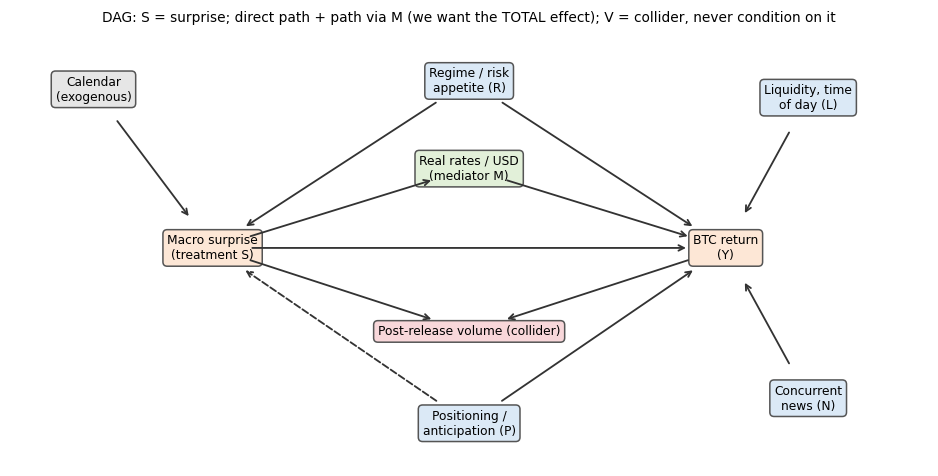

In [3]:
# DAG ---------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.6, 4.4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5.2)
N = {"S": (2.2, 2.6, "Macro surprise\n(treatment S)", "#fde7d6"), "Y": (7.8, 2.6, "BTC return\n(Y)", "#fde7d6"),
     "C": (0.9, 4.5, "Calendar\n(exogenous)", "#e6e6e6"), "R": (5.0, 4.6, "Regime / risk\nappetite (R)", "#dbe9f6"),
     "P": (5.0, 0.5, "Positioning /\nanticipation (P)", "#dbe9f6"), "L": (8.7, 4.4, "Liquidity, time\nof day (L)", "#dbe9f6"),
     "N": (8.7, 0.8, "Concurrent\nnews (N)", "#dbe9f6"), "M": (5.0, 3.55, "Real rates / USD\n(mediator M)", "#e2f0d9"),
     "V": (5.0, 1.6, "Post-release volume (collider)", "#f8d7da")}
for k, (x, y, t, c) in N.items():
    ax.text(x, y, t, ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round,pad=.35", fc=c, ec="#555"))
def arr(a, b, dashed=False, rad=0.0):
    (x1, y1, *_), (x2, y2, *_) = N[a], N[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#333", lw=1.2,
                ls="--" if dashed else "-", shrinkA=26, shrinkB=26, connectionstyle=f"arc3,rad={rad}"))
for a, b in [("S","M"),("M","Y"),("S","Y"),("R","S"),("R","Y"),("P","Y"),("N","Y"),("L","Y"),("C","S")]: arr(a, b)
arr("P","S",dashed=True); arr("S","V"); arr("Y","V")
ax.set_title("DAG: S = surprise; direct path + path via M (we want the TOTAL effect); V = collider, never condition on it", fontsize=9)
banner(ax); plt.tight_layout(); plt.savefig(FIG/"dag.png"); plt.show()

**Reading the DAG (backdoor criterion)**

| Path | Role | How the analysis handles it |
|---|---|---|
| $S \to Y$ and $S \to M \to Y$ | **total** effect we want (real rates/USD = channel) | do **not** control for $M$ (it would block part of the effect) |
| $S \leftarrow R \to Y$ | confounder: volatility regime / risk appetite | closed by the **choice of donors** (±180 days) and the synthetic-day covariates (24 h volatility, 24 h return, volume) |
| $S \leftarrow C$ | the calendar sets *when* $S$ arrives; exogenous to BTC | central identification argument |
| $P \to Y$, $P \dashrightarrow S$ (anticipation) | positioning before the release | tested with the **pre-window** (event study, Wald) and the synthetic-day pre-fit |
| $N \to Y$ | concurrent news (Fed speakers, crypto news) | unobserved → **limitation** (see §10) |
| $S \to V \leftarrow Y$ | collider: post-release volume | **never** condition on it |

## 3. Data

In [4]:
if REAL:
    px = load_prices(DATA/"btcusdt_1m.parquet")
    px = px[px.index <= DATA_END]       # fixed sample end, so a later download gives the same results
    ev = pd.read_csv(DATA/"events.csv", dtype={"date_ny": str, "time_ny": str})
    # Unscheduled FRED dates (annual seasonal-factor / benchmark revisions), spotted in 5.5(e):
    # actual releases = CPI 10 Feb 2022, 14 Feb 2023, 13 Feb 2024; NFP 5 Jan 2024, 2 Aug 2024
    SPURIOUS = ["2022-02-08", "2023-02-10", "2024-02-09", "2024-01-10", "2024-08-21"]
    ev = ev[~ev.date_ny.isin(SPURIOUS)].reset_index(drop=True)
    o830 = pd.read_csv(DATA/"other_0830_dates.csv", dtype=str).iloc[:, 0].tolist()
    o1400 = pd.read_csv(DATA/"other_1400_dates.csv", dtype=str).iloc[:, 0].tolist() if (DATA/"other_1400_dates.csv").exists() and (DATA/"other_1400_dates.csv").stat().st_size > 12 else []
    # --- surprises: FOMC (Bauer-Swanson, column 'surprise' if present) + CPI/NFP (Investing.com consensus, data/surprises_manual.csv)
    ev["surprise_z"] = np.nan
    if "surprise" in ev:
        m = ev.event_type.eq("FOMC") & ev.surprise.notna()
        ev.loc[m, "surprise_z"] = (ev.loc[m, "surprise"] - ev.loc[m, "surprise"].mean()) / ev.loc[m, "surprise"].std()
    f = DATA/"surprises_manual.csv"        # columns: event_type, date_ny, actual, consensus
    if f.exists():
        sm = pd.read_csv(f, dtype={"date_ny": str}); sm["s"] = sm.actual - sm.consensus
        sm["z"] = sm.groupby("event_type").s.transform(lambda x: (x - x.mean()) / x.std())
        ev = ev.merge(sm[["event_type", "date_ny", "z"]], on=["event_type", "date_ny"], how="left")
        ev["surprise_z"] = ev.surprise_z.fillna(ev.z); ev = ev.drop(columns="z")
else:
    ev, o830 = simulate_calendar()
    o1400 = []
    px = load_prices(simulate_btc(ev))
    print("True injected effect:", TRUTH)

EXCL = {"08:30": o830, "14:00": o1400}
lo_d, hi_d = (px.index.min() + pd.Timedelta(days=3)).strftime("%Y-%m-%d"), (px.index.max() - pd.Timedelta(days=3)).strftime("%Y-%m-%d")
ev = ev[(ev.date_ny >= lo_d) & (ev.date_ny <= hi_d)].reset_index(drop=True)
P_ = Prices(px)

print(f"BTC 1 min: {px.index.min():%Y-%m-%d} -> {px.index.max():%Y-%m-%d} | {len(px):,} bars | "
      f"{px.close.isna().mean():.4%} missing after ffill(3)")
display(ev.assign(year=ev.date_ny.str[:4]).groupby(["year", "event_type"]).size().unstack(fill_value=0))
print("Surprise available for", int(ev.surprise_z.notna().sum()), "/", len(ev), "events")

BTC 1 min: 2022-01-01 -> 2026-10-15 | 2,517,120 bars | 0.0031% missing after ffill(3)


event_type,CPI,FOMC,NFP
year,,,
2022,12,8,12
2023,12,8,12
2024,12,8,12
2025,11,8,11
2026,9,6,10


Surprise available for 128 / 151 events


## 4. Event windows and donor pool
For each event: 5-minute path from −120 to +120 min; donors = business days **without** a release at the same New York clock time
(we exclude Thursdays at 08:30 = jobless claims, PPI, retail sales, US holidays and all treated days),
within ±180 days of the event. Matching covariates: 24 h volatility, 24 h return (normalised), volume over the previous 2 h.

[08:30 NY] events: 113 (valid 113) | donor days in total: 326 | donors per event (median): 66 | lambda* = 0.1
[14:00 NY] events: 38 (valid 38) | donor days in total: 1120 | donors per event (median): 231 | lambda* = 0.03
Usable events: 151 / 151


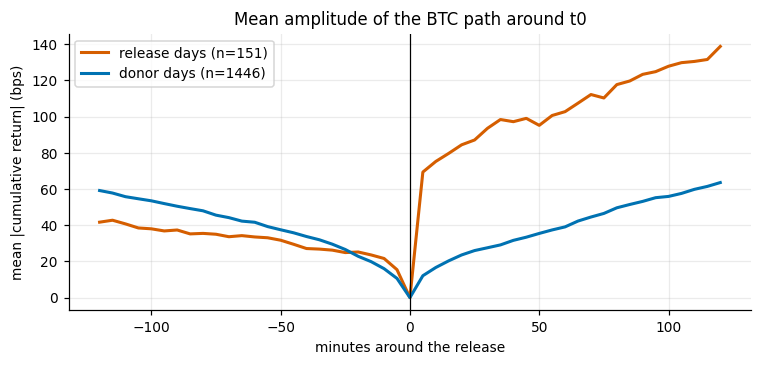

In [5]:
groups = {c: g.reset_index(drop=True) for c, g in ev.groupby("time_ny") if len(g)}
ES = {}
for clock, g in groups.items():
    es = EventStudy(P_, g, EXCL, donor_window_days=180)
    es.did()
    sc_lambda = es.tune_lambda()
    es.sc(n_placebo=100, seed=SEED)
    ES[clock] = es
    print(f"[{clock} NY] events: {len(g)} (valid {int(es.ev.ok.sum())}) | donor days in total: {len(es.pools[clock]['dates'])} "
          f"| donors per event (median): {int(np.median(es.res['did']['nj'][es.ev.ok.values]))} | lambda* = {es.lam}")

EV = pd.concat([es.ev for es in ES.values()], ignore_index=True)
GAP_DID = np.vstack([es.res["did"]["gap"] for es in ES.values()])
DLRV = np.concatenate([es.res["did"]["dlogrv"] for es in ES.values()])
SC = {k: np.concatenate([es.res["sc"][k] for es in ES.values()]) for k in ["rm_pre","rm_post","ratio","s30","p_ratio","p_s30","eff_n","pl_s30_mean"]}
GAP_SC = np.vstack([es.res["sc"]["gap_bps"] for es in ES.values()])
VALID = np.isfinite(GAP_DID).all(1) & np.isfinite(GAP_SC).all(1)
print("Usable events:", int(VALID.sum()), "/", len(EV))

# Mean |cumulative return| path: release days vs donor days
fig, ax = plt.subplots(1, 1, figsize=(7, 3.4))
ys = np.vstack([es.ev_w["path"] for es in ES.values()])[VALID]
dn = np.vstack([es.pools[c]["path"] for c, es in ES.items()])
ax.plot(TAUS, np.abs(ys).mean(0), color=C_T, lw=2, label=f"release days (n={len(ys)})")
ax.plot(TAUS, np.abs(dn).mean(0), color=C_D, lw=2, label=f"donor days (n={len(dn)})")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("minutes around the release"); ax.set_ylabel("mean |cumulative return| (bps)")
ax.set_title("Mean amplitude of the BTC path around t0"); ax.legend(); banner(ax); plt.tight_layout(); plt.savefig(FIG/"paths_abs.png"); plt.show()

## 5. DiD: equal donor weights, parallel-trends test

### 5.0 Naive difference versus DiD (2 × 2 table, as in the course's tutoring example)
Log realised volatility (5-minute increments) in the 30 minutes before and after the release clock time, release days versus donor days.
Two naive comparisons are possible: **after only** (treated − donors after t0), biased if release days are already more agitated before;
**before/after** on treated days only, biased if volatility rises at that hour anyway. The DiD removes both biases.

In [6]:
# 5.0 2x2 table: log RV before / after, treated / donors (means over the whole pool, not matched)
rows = []
for c, es in ES.items():
    ok = es.ev.ok.values; P = es.pools[c]
    tp, tq = log_rv(es.ev_w["path"], I0 - 6, I0)[ok].mean(), log_rv(es.ev_w["path"], I0, I0 + 6)[ok].mean()
    dp, dq = log_rv(P["path"], I0 - 6, I0).mean(), log_rv(P["path"], I0, I0 + 6).mean()
    rows.append({"clock": c, "n_treated": int(ok.sum()), "n_donors": len(P["path"]), "treated_before": tp, "treated_after": tq,
                 "donors_before": dp, "donors_after": dq, "naive_after_only": tq - dq, "naive_before_after": tq - tp,
                 "selection_bias_before": tp - dp, "DiD_2x2": (tq - tp) - (dq - dp)})
NAIVE = pd.DataFrame(rows).set_index("clock"); display(NAIVE.round(3))
print("Reading: volatility multiplier = exp(value). The matched DiD (§5.4, donors within ±180 days of each event) is the retained estimate.")
print("At 14:00, FOMC days are already more volatile BEFORE the decision (selection bias): the after-only comparison overstates the effect.")

,n_treated,n_donors,treated_before,treated_after,donors_before,donors_after,naive_after_only,naive_before_after,selection_bias_before,DiD_2x2
clock,,,,,,,,,,
08:30,113,326,3.375,4.342,3.299,3.295,1.047,0.966,0.077,0.970
14:00,38,1120,3.702,4.313,3.425,3.419,0.893,0.610,0.278,0.616


Reading: volatility multiplier = exp(value). The matched DiD (§5.4, donors within ±180 days of each event) is the retained estimate.
At 14:00, FOMC days are already more volatile BEFORE the decision (selection bias): the after-only comparison overstates the effect.


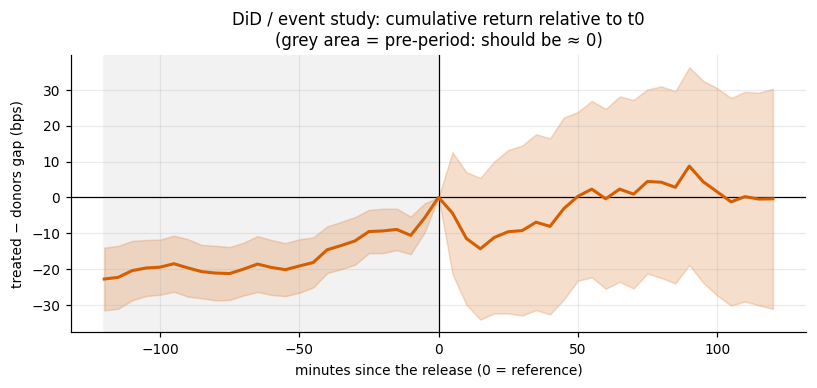

Pre-trend test (H0: gap = 0 over the whole pre-period)
  {'wald': 64.37, 'df': 24, 'p_wald': 0.0, 'max_abs_t': 5.642, 'p_maxt_signflip': 0.0, 'n_events': 151}


,horizon_min,n_events,att_bps,se,ci_low,ci_high
0,5,151,-4.41,8.67,-21.39,12.58
1,15,151,-14.35,10.08,-34.11,5.41
2,30,151,-9.29,12.09,-32.99,14.42
3,60,151,-0.41,12.80,-25.50,24.68
4,120,151,-0.42,15.66,-31.12,30.29


Volatility DiD: 0.879 (SE 0.051) -> realised vol at 30 min is x2.41 vs days without a release; t = 17.2; 95% CI x2.18 to x2.66


In [7]:
# 5.1 Event study: mean treated − donors gap, with 95% CI (SE across events)
g = GAP_DID[VALID]; m, se = g.mean(0), g.std(0, ddof=1) / np.sqrt(len(g))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axvspan(-120, 0, color="#f2f2f2"); ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=.8)
ax.fill_between(TAUS, m - 1.96*se, m + 1.96*se, color=C_T, alpha=.2); ax.plot(TAUS, m, color=C_T, lw=2)
ax.set_xlabel("minutes since the release (0 = reference)"); ax.set_ylabel("treated − donors gap (bps)")
ax.set_title("DiD / event study: cumulative return relative to t0\n(grey area = pre-period: should be ≈ 0)")
banner(ax); plt.tight_layout(); plt.savefig(FIG/"did_event_study.png"); plt.show()

# 5.2 Parallel trends: p_maxt_signflip = reliable joint test; the Wald test is fragile (24 highly correlated points)
pt = pretrend_test(GAP_DID[VALID]); print("Pre-trend test (H0: gap = 0 over the whole pre-period)\n ", {k: round(v, 3) for k, v in pt.items()})

# 5.3 ATT by horizon (signed mean effect: expected ≈ 0 because positive and negative surprises offset)
att = att_table(GAP_DID[VALID]); display(att.round(2))

# 5.4 Volatility DiD: ln(RV[0,30]/RV[-30,0]) treated − donors
d = DLRV[VALID]; mm, ss = d.mean(), d.std(ddof=1)/np.sqrt(len(d))
print(f"Volatility DiD: {mm:.3f} (SE {ss:.3f}) -> realised vol at 30 min is x{np.exp(mm):.2f} vs days without a release; t = {mm/ss:.1f}"
      f"; 95% CI x{np.exp(mm - 1.96*ss):.2f} to x{np.exp(mm + 1.96*ss):.2f}")
DID_VOL = dict(att=float(mm), se=float(ss), n=int(len(d)))

### 5.5 Diagnostics: why parallel trends might be rejected
If the Wald test rejects, there are three possible explanations: (a) **genuine anticipation**; (b) **poorly matched donors** (weekday composition, regime);
(c) **artefact** (extreme values, or a time offset in the data). We test them one by one.

5 largest |t| in the pre-period:
 tau_min  gap_bps     t
     -75   -21.27 -5.64
     -85   -20.74 -5.46
     -80   -21.13 -5.44
     -55   -20.18 -5.35
     -70   -20.03 -5.33

Winsorised 5/95 Wald: {'wald': 88.255, 'df': 24, 'p_wald': 0.0, 'max_abs_t': 6.898, 'p_maxt_signflip': 0.0, 'n_events': 151}
Median gap at tau=-120: -16.1 bps | mean: -22.8 bps

Same-weekday DiD (n=78), pre-trend: {'wald': 73.428, 'df': 24, 'p_wald': 0.0, 'max_abs_t': 5.236, 'p_maxt_signflip': 0.0, 'n_events': 78}
Event weekdays: {'Wednesday': 60, 'Friday': 57, 'Thursday': 17, 'Tuesday': 17}


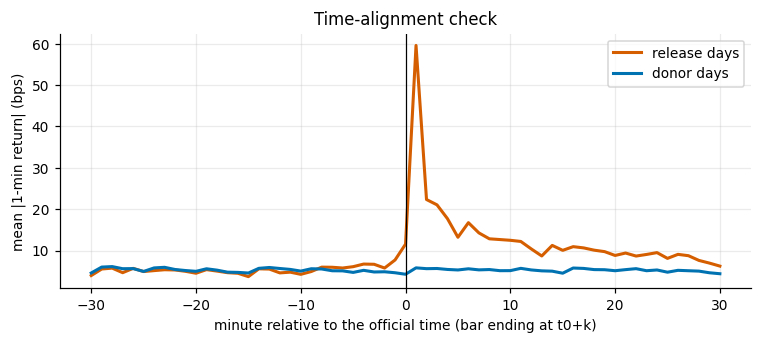

Peak minute (events): k = 1 -> expected: 1 or 2 (the bar that contains 08:30:00)

Months with >1 event of the same type: 0


In [8]:
# (a) where is the pre-trend gap?
g = GAP_DID[VALID]; m = g.mean(0); se = g.std(0, ddof=1)/np.sqrt(len(g)); t = m/se
tab = pd.DataFrame({"tau_min": TAUS, "gap_bps": m, "t": t})[PRE]
print("5 largest |t| in the pre-period:"); print(tab.reindex(tab.t.abs().sort_values(ascending=False).index).head(5).round(2).to_string(index=False))

# (b) robustness to extreme values: winsorise each column at 5/95%
lo, hi = np.percentile(g, [5, 95], axis=0); gw = np.clip(g, lo, hi)
print("\nWinsorised 5/95 Wald:", {k: round(v, 3) for k, v in pretrend_test(gw).items()})
print("Median gap at tau=-120:", round(float(np.median(g[:, 0])), 1), "bps | mean:", round(float(m[0]), 1), "bps")

# (c) donors on the SAME weekday as the event
def did_same_dow(es):
    gap = np.full((len(es.ev), len(TAUS)), np.nan)
    for i in range(len(es.ev)):
        if not es.ev.ok.iloc[i]: continue
        dj, P = es.donors(i); dow = pd.Timestamp(es.ev.date_ny.iloc[i]).dayofweek
        dj = dj[P["dates"][dj].dayofweek == dow]
        if len(dj) >= 5: gap[i] = es.ev_w["path"][i] - P["path"][dj].mean(0)
    return gap
gd = np.vstack([did_same_dow(es) for es in ES.values()]); okd = np.isfinite(gd).all(1)
print(f"\nSame-weekday DiD (n={int(okd.sum())}), pre-trend:", {k: round(v, 3) for k, v in pretrend_test(gd[okd]).items()})
print("Event weekdays:", EV.assign(d=pd.to_datetime(EV.date_ny).dt.day_name()).d.value_counts().to_dict())

# (d) time alignment: the peak of |1-min return| must appear just AFTER t0 (offset +1, +2, ...)
offs = np.arange(-30, 31); r1 = np.abs(np.diff(P_.lp, prepend=np.nan)) * 1e4
def mean_abs(t0s):
    pos = np.round((pd.DatetimeIndex(t0s) - P_.start).total_seconds().to_numpy() / 60).astype(int)
    pos = pos[(pos > 40) & (pos < len(r1) - 40)]
    return np.nanmean(r1[pos[:, None] + offs[None, :]], axis=0)
a_ev = mean_abs(EV.t0)
a_dn = mean_abs([to_utc(d.strftime("%Y-%m-%d"), c) for c, es in ES.items() for d in es.pools[c]["dates"]])
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.plot(offs, a_ev, color=C_T, lw=2, label="release days"); ax.plot(offs, a_dn, color=C_D, lw=2, label="donor days")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("minute relative to the official time (bar ending at t0+k)"); ax.set_ylabel("mean |1-min return| (bps)")
ax.set_title("Time-alignment check"); ax.legend(); banner(ax); plt.tight_layout(); plt.savefig(FIG/"alignment_check.png"); plt.show()
print("Peak minute (events): k =", int(offs[np.argmax(a_ev)]), "-> expected: 1 or 2 (the bar that contains 08:30:00)")

# (e) duplicates in the calendar (>1 event of the same type in a month)
cnt = ev.assign(ym=ev.date_ny.str[:7]).groupby(["event_type", "ym"]).size()
dup = cnt[cnt > 1]
print("\nMonths with >1 event of the same type:", len(dup))
if len(dup): print(ev.assign(ym=ev.date_ny.str[:7]).merge(dup.rename("n").reset_index(), on=["event_type", "ym"]).sort_values("date_ny")[["event_type", "date_ny"]].to_string(index=False))

In [9]:
# 5.6 Is the pre-drift specific to the release time (anticipation) or general (selection of event / donor days)?
print("Mean path (bps, relative to t0), treated vs donors:")
for tt in (-120, -60, -30):
    k = np.where(TAUS == tt)[0][0]; print(f"  tau={tt:4d}: treated {ys.mean(0)[k]:6.1f} | donors {dn.mean(0)[k]:6.1f}")
k60 = np.where(TAUS == -60)[0][0]; rows = []
base = ev[ev.time_ny == "08:30"].reset_index(drop=True)
for shift in (0, -720, -360, 360):
    es = ES["08:30"] if shift == 0 else EventStudy(P_, base, EXCL, shift_min=shift)
    r = es.res["did"] if shift == 0 else es.did()
    ok = np.isfinite(r["gap"]).all(1); gg = r["gap"][ok]; pt = pretrend_test(gg, n_flip=3000)
    rows.append(dict(shift_h=shift/60, n=int(ok.sum()), gap_tau60_bps=gg[:, k60].mean(),
                     t_tau60=gg[:, k60].mean()/(gg[:, k60].std(ddof=1)/np.sqrt(ok.sum())), max_abs_t=pt["max_abs_t"], p_maxt=pt["p_maxt_signflip"]))
display(pd.DataFrame(rows).round(3))
print("-> drift only at shift 0: anticipation specific to the release; also at other times: selection bias between event and donor days.")
print("\nStability of the gap at tau=-60:")
for lab, msk in [("CPI", EV.event_type == "CPI"), ("NFP", EV.event_type == "NFP")] + [(y, EV.date_ny.str[:4] == y) for y in sorted(EV.date_ny.str[:4].unique())]:
    mk = VALID & msk.to_numpy(); x = GAP_DID[mk, k60]
    if mk.sum() > 5: print(f"  {lab:5s} n={int(mk.sum()):3d} | {x.mean():6.1f} bps (t = {x.mean()/(x.std(ddof=1)/np.sqrt(len(x))):5.1f})")

Mean path (bps, relative to t0), treated vs donors:
  tau=-120: treated  -22.6 | donors    2.4
  tau= -60: treated  -18.5 | donors    1.4
  tau= -30: treated  -12.5 | donors   -0.2


,shift_h,n,gap_tau60_bps,t_tau60,max_abs_t,p_maxt
0,0.0,113,-16.164,-4.803,4.897,0.000
1,-12.0,113,-1.804,-0.464,2.361,0.136
2,-6.0,113,-3.422,-0.772,1.683,0.445
3,6.0,113,7.501,1.294,3.492,0.010


-> drift only at shift 0: anticipation specific to the release; also at other times: selection bias between event and donor days.

Stability of the gap at tau=-60:
  CPI   n= 56 |  -24.6 bps (t =  -4.9)
  NFP   n= 57 |   -7.9 bps (t =  -1.8)
  2022  n= 32 |  -36.2 bps (t =  -2.6)
  2023  n= 32 |   -4.8 bps (t =  -1.3)
  2024  n= 32 |  -17.7 bps (t =  -2.2)
  2025  n= 30 |  -22.4 bps (t =  -3.5)
  2026  n= 25 |  -16.1 bps (t =  -2.7)


### 5.7 Placebo-calibrated DiD inference (corrects for donors shared across events)
Standard errors "across events" are too small: a CPI and an NFP in the same month use almost the same donor days, so their gaps are correlated.
We calibrate by drawing **fake events** among donor days (same ±180-day windows) and looking at the distribution of the mean gap and of the pre-trend max|t| under H0.

Pre-trend: observed max|t| = 5.64 | under placebo: median 2.15, 95th pct 3.67 -> calibrated p = 0.002


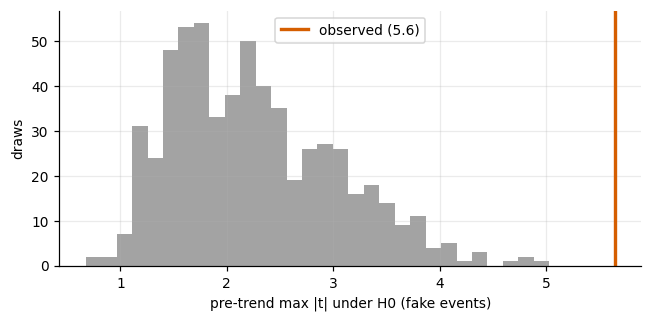

,tau_min,gap_bps,SE_naive,SE_calibrated,t_calibrated,p_placebo
0,-120,-22.790,4.460,7.185,-3.172,0.002
1,-90,-19.681,4.096,6.195,-3.177,0.003
2,-60,-19.566,3.909,4.994,-3.918,0.002
3,-30,-12.164,3.395,4.050,-3.003,0.003


-> Pre-period only: under H0 there is no shock, so the placebo is a genuine null distribution. SE_calibrated > SE_naive = donor sharing. In the post-period, the release INCREASES the variance: do not use this placebo for signed ATTs (it would be too optimistic); keep the SE across events or the Fisher permutation (§7).


[08:30] n = 113 | gap at -60 min = -16.2 bps | max|t| = 4.90 | calibrated p = 0.003


[14:00] n = 38 | gap at -60 min = -29.7 bps | max|t| = 3.49 | calibrated p = 0.010


In [10]:
pool = ES["08:30"].pools["08:30"]; E_ev = int(VALID.sum())
means0, tmax0 = placebo_did(pool, 180, E_ev, n_draw=600, seed=SEED)
obs = pretrend_test(GAP_DID[VALID], n_flip=500)["max_abs_t"]
p_cal = (1 + (tmax0 >= obs).sum()) / (len(tmax0) + 1)
print(f"Pre-trend: observed max|t| = {obs:.2f} | under placebo: median {np.median(tmax0):.2f}, 95th pct {np.percentile(tmax0, 95):.2f} -> calibrated p = {p_cal:.3f}")
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(tmax0, bins=30, color=C_G, alpha=.8); ax.axvline(obs, color=C_T, lw=2.2, label=f"observed ({obs:.1f})")
ax.set_xlabel("pre-trend max |t| under H0 (fake events)"); ax.set_ylabel("draws"); ax.legend(); banner(ax); plt.tight_layout(); plt.savefig(FIG/"pretrend_placebo.png"); plt.show()

rows = []
for h in (-120, -90, -60, -30):
    k = np.where(TAUS == h)[0][0]; x = GAP_DID[VALID, k]
    se_n, se_c = x.std(ddof=1)/np.sqrt(len(x)), means0[:, k].std()
    rows.append(dict(tau_min=h, gap_bps=x.mean(), SE_naive=se_n, SE_calibrated=se_c, t_calibrated=x.mean()/se_c, p_placebo=(1 + (np.abs(means0[:, k]) >= abs(x.mean())).sum())/(len(means0)+1)))
display(pd.DataFrame(rows).round(3))
print("-> Pre-period only: under H0 there is no shock, so the placebo is a genuine null distribution. SE_calibrated > SE_naive = donor sharing. In the post-period, the release INCREASES the variance: do not use this placebo for signed ATTs (it would be too optimistic); keep the SE across events or the Fisher permutation (§7).")

# Check: the same test run separately by clock (the reference placebo above draws its fake events from the 08:30 pool)
for clock, es in ES.items():
    mk = VALID & (EV.time_ny == clock).to_numpy()
    o = pretrend_test(GAP_DID[mk], n_flip=500)["max_abs_t"]
    _, tm = placebo_did(es.pools[clock], 180, int(mk.sum()), n_draw=600, seed=SEED)
    k60 = np.where(TAUS == -60)[0][0]
    print(f"[{clock}] n = {int(mk.sum())} | gap at -60 min = {GAP_DID[mk, k60].mean():.1f} bps | max|t| = {o:.2f} | calibrated p = {(1 + (tm >= o).sum()) / (len(tm) + 1):.3f}")

## 6. Synthetic control: the "synthetic day"
For each event, we build a **counterfactual BTC** as a weighted combination of BTC paths at the same clock time
on **donor days** (untreated by construction). Weights come from a *ridge* regression on the pre-window normalised by its volatility
+ covariates (no sum-to-one constraint: BTC is not inside the convex hull of a pool that is too calm; see Doudchenko-Imbens, *augmented SC*).
$\lambda$ is chosen by validation on placebo days (never on treated days).
**Inference**: in-space placebos: each donor day becomes a "fake treated" unit; we compare the post/pre RMSPE ratio and the mean absolute gap over 30 min.

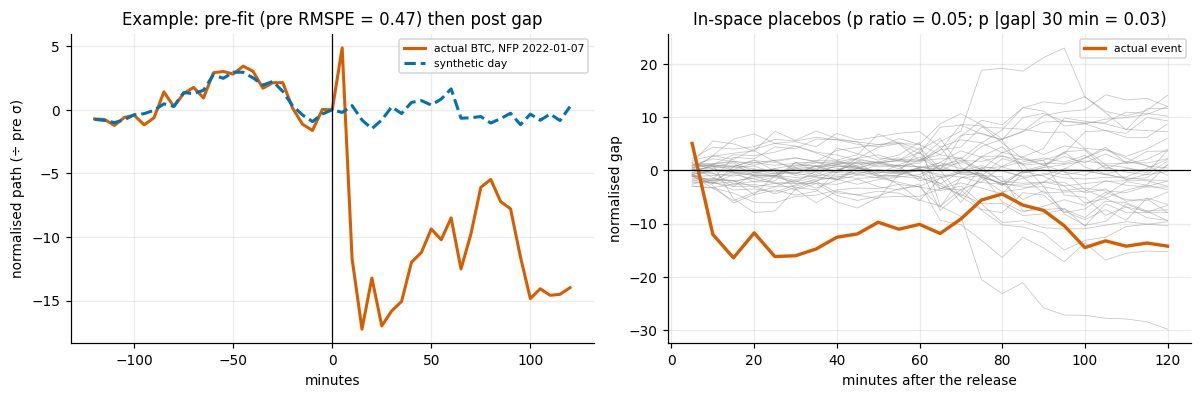

post/pre RMSPE ratio      : 32/151 events with p<0.05 (21%; under H0 ≈ 5%), one-sided binomial test p = 3.8e-12
mean |gap| 0-30 min       : 62/151 events with p<0.05 (41%; under H0 ≈ 5%), one-sided binomial test p = 4e-40
|gap| 0-30 min, treated / placebo mean: median 2.50 (1 = no effect)
Fit quality: median normalised pre RMSPE = 0.46 | median effective number of donors = 44.5


In [11]:
first = next(iter(ES.values())); i = int(np.where(first.ev.ok.values)[0][0])
ex = first.sc_example(i); sc = first.res["sc"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
ax = axs[0]
ax.plot(ex["taus"], ex["y"], color=C_T, lw=2, label=f"actual BTC, {first.ev.event_type[i]} {first.ev.date_ny[i]}")
ax.plot(ex["taus"], ex["synth"], color=C_D, lw=2, ls="--", label="synthetic day")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("minutes"); ax.set_ylabel("normalised path (÷ pre σ)"); ax.legend(fontsize=7)
ax.set_title(f"Example: pre-fit (pre RMSPE = {sc['rm_pre'][i]:.2f}) then post gap"); banner(ax)
ax = axs[1]
for pg in sc["pl_gap"][i]: ax.plot(TAUS[POST], pg, color=C_G, lw=.5, alpha=.5)
ax.plot(TAUS[POST], sc["gap_bps"][i] / first.ev.sigma[i], color=C_T, lw=2.2, label="actual event")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("minutes after the release"); ax.set_ylabel("normalised gap")
ax.set_title(f"In-space placebos (p ratio = {sc['p_ratio'][i]:.2f}; p |gap| 30 min = {sc['p_s30'][i]:.2f})"); ax.legend(fontsize=7); banner(ax)
plt.tight_layout(); plt.savefig(FIG/"sc_example.png"); plt.show()

v = VALID
n_ev = int(v.sum())
for name, p in [("post/pre RMSPE ratio", SC["p_ratio"][v]), ("mean |gap| 0-30 min", SC["p_s30"][v])]:
    k = int((p < .05).sum()); bt = stats.binomtest(k, n_ev, .05, alternative="greater")
    print(f"{name:26s}: {k}/{n_ev} events with p<0.05 ({k/n_ev:.0%}; under H0 ≈ 5%), one-sided binomial test p = {bt.pvalue:.2g}")
ex_ratio = SC["s30"][v] / SC["pl_s30_mean"][v]
print(f"|gap| 0-30 min, treated / placebo mean: median {np.median(ex_ratio):.2f} (1 = no effect)")
print(f"Fit quality: median normalised pre RMSPE = {np.median(SC['rm_pre'][v]):.2f} | median effective number of donors = {np.median(SC['eff_n'][v]):.1f}")
SC_SUM = dict(share_p05_s30=float((SC["p_s30"][v] < .05).mean()), median_excess=float(np.median(ex_ratio)), n=n_ev)

> **Note for the report.** The RMSPE ratio is high *by construction* when the pool has more donors than pre-period points
> (the ridge overfits the pre-period): only the **comparison with placebos** (same procedure) can be interpreted. We also
> report the effective number of donors and the out-of-sample fit (lambda chosen by validation).

### 6.2 Classical synthetic control (robustness)
Constrained weights (≥ 0, sum to 1): the counterfactual is a genuine weighted average of donor days, without extrapolation.
Expected: conclusions close to the ridge version, a slightly worse pre-fit and few effective donors (concentrated weights).
If both methods agree, the result does not depend on the choice of weights.

In [12]:
# 6.2 Classical synthetic control (weights >= 0, sum 1): comparison with the ridge synthetic day
# The ridge allows negative weights (extrapolation); the classical version stays inside the convex hull of the donors.
SC_CL = {}
for clock, es in ES.items():
    SC_CL[clock] = es.sc(n_placebo=100, seed=SEED, method="simplex")
cl = {k: np.concatenate([SC_CL[c][k] for c in ES]) for k in ["rm_pre", "ratio", "s30", "p_ratio", "p_s30", "eff_n", "pl_s30_mean"]}
GAP_CL = np.vstack([SC_CL[c]["gap_bps"] for c in ES])
v = VALID & np.isfinite(GAP_CL).all(1); n_ev = int(v.sum())
rows = []
for name, d in [("ridge (synthetic day)", SC), ("classical (simplex)", cl)]:
    k = int((d["p_s30"][v] < .05).sum()); bt = stats.binomtest(k, n_ev, .05, alternative="greater")
    rows.append({"method": name, "n": n_ev, "share p<0.05": k / n_ev, "binomial test p": bt.pvalue,
                 "median pre RMSPE": np.median(d["rm_pre"][v]), "effective donors (median)": np.median(d["eff_n"][v]),
                 "excess |gap| 0-30 min / placebo": np.median(d["s30"][v] / d["pl_s30_mean"][v])})
display(pd.DataFrame(rows).round(3))
print("correlation of 0-30 min |gaps| between the two methods:", round(np.corrcoef(SC["s30"][v], cl["s30"][v])[0, 1], 3))
SC_CLASSIC_SUM = dict(share_p05_s30=float((cl["p_s30"][v] < .05).mean()), n=n_ev)

,method,n,share p<0.05,binomial test p,median pre RMSPE,effective donors (median),excess |gap| 0-30 min / placebo
0,ridge (synthetic day),151,0.411,0.0,0.462,44.475,2.498
1,classical (simplex),151,0.444,0.0,0.647,4.915,2.405


correlation of 0-30 min |gaps| between the two methods: 0.988


## 7. Directional effect: BTC reaction to the surprise

,horizon_min,method,slope_bps_per_sd,se_hc1,p_hc1,p_perm,n
0,5,DiD,-64.803,11.436,0.0,0.0,128
1,5,Synthetic day,-64.873,11.484,0.0,0.0,128
2,15,DiD,-65.666,15.066,0.0,0.0,128
3,15,Synthetic day,-67.121,14.923,0.0,0.0,128
4,30,DiD,-78.691,19.222,0.0,0.0,128
5,30,Synthetic day,-79.894,19.027,0.0,0.0,128
6,60,DiD,-73.672,18.825,0.0,0.0,128
7,60,Synthetic day,-74.974,18.067,0.0,0.0,128


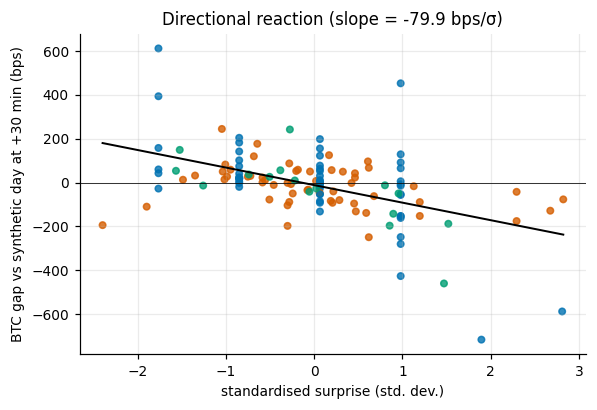

,subsample,horizon_min,slope_bps_per_sd,se_hc1,p_hc1,p_perm,n,p_perm_bonf4
0,All types,5,-64.873,11.484,0.000,0.000,128,0.001
1,All types,30,-79.894,19.027,0.000,0.000,128,0.001
2,CPI (core),5,-92.738,18.065,0.000,0.000,55,0.001
3,CPI (core),30,-123.033,32.498,0.000,0.000,55,0.001
4,NFP,5,-26.314,6.205,0.000,0.001,57,0.004
5,NFP,30,-29.128,14.365,0.043,0.022,57,0.087
6,FOMC (2022-23),5,-109.553,36.939,0.003,0.001,16,0.004
7,FOMC (2022-23),30,-115.756,32.811,0.000,0.001,16,0.004
8,CPI + NFP,5,-58.769,11.691,0.000,0.000,112,0.001
9,CPI + NFP,30,-74.989,21.098,0.000,0.000,112,0.001


Negative slope in 20 / 20 sub-samples; p_perm < 0.05 after Bonferroni in 18


,horizon_min,OLS,OLS_winsorised_5pct,Theil_Sen,Spearman,p_Spearman
0,5,-64.873,-49.280,-48.926,-0.578,0.0
1,30,-79.894,-52.467,-61.484,-0.485,0.0


,tau_min,slope_bps_per_sd,se_hc1,p_hc1,p_perm,n
0,-60,-8.544,5.144,0.097,0.037,128
1,-30,-5.754,4.644,0.215,0.128,128


Expected: slope ≈ 0 before t0. Observed: -60 min -> -8.5 bps/σ (p = 0.04), -30 min -> -5.8 bps/σ (p = 0.13)


In [13]:
z = EV.surprise_z.to_numpy(); has_z = np.isfinite(z) & VALID
if has_z.sum() < 15:
    print("Surprises unavailable (< 15 events): provide data/surprises_manual.csv (actual, consensus) and/or the Bauer-Swanson file.")
else:
    rows = []
    for h in (5, 15, 30, 60):
        kd, ks = np.where(TAUS == h)[0][0], np.where(TAUS[POST] == h)[0][0]
        for meth, G, k in (("DiD", GAP_DID, kd), ("Synthetic day", GAP_SC, ks)):
            r = directional(G[:, k], np.where(has_z, z, np.nan), n_perm=3000, seed=SEED, groups=EV.event_type.to_numpy())
            rows.append(dict(horizon_min=h, method=meth, **r))
    DIR = pd.DataFrame(rows); display(DIR.round(3))
    fig, ax = plt.subplots(figsize=(5.5, 3.8)); k = np.where(TAUS[POST] == 30)[0][0]
    cols = EV.event_type.map({"CPI": C_D, "NFP": C_T, "FOMC": "#009E73"})
    ax.scatter(z[has_z], GAP_SC[has_z, k], c=cols[has_z], s=18, alpha=.8)
    b = np.polyfit(z[has_z], GAP_SC[has_z, k], 1); xs = np.linspace(np.nanmin(z), np.nanmax(z), 20); ax.plot(xs, np.polyval(b, xs), color="k", lw=1.3)
    ax.axhline(0, color="k", lw=.5); ax.set_xlabel("standardised surprise (std. dev.)"); ax.set_ylabel("BTC gap vs synthetic day at +30 min (bps)")
    ax.set_title(f"Directional reaction (slope = {b[0]:.1f} bps/σ)"); banner(ax); plt.tight_layout(); plt.savefig(FIG/"directional.png"); plt.show()
    if MODE == "SIMULATED": print(f"(Simulation: true slope = {TRUTH['beta_bps_per_sd']} bps/σ at +30 min)")

    # --- 7.2 Robustness of the slope (synthetic day, 5 and 30 min) ---------------------------------------------
    # Reminder: 4 horizons tested => Bonferroni correction (p x 4); per-type slopes are not comparable in level
    # (a surprise "σ" does not mean the same thing for a CPI, an NFP or an FOMC decision).
    d_ev = pd.to_datetime(EV.date_ny)
    def slope(mask, h, label):
        ks = np.where(TAUS[POST] == h)[0][0]
        zz = np.where(mask & has_z, z, np.nan)
        if np.isfinite(zz).sum() < 8: return None
        r = directional(GAP_SC[:, ks], zz, n_perm=3000, seed=SEED, groups=EV.event_type.to_numpy())
        return dict(subsample=label, horizon_min=h, **r)
    tp = EV.event_type.to_numpy(); allm = np.ones(len(EV), bool)
    top = np.zeros(len(EV), bool); idx = np.argsort(-np.abs(np.where(has_z, z, 0)))[:5]; top[idx] = True
    subs = {"All types": allm, "CPI (core)": tp == "CPI", "NFP": tp == "NFP", "FOMC (2022-23)": tp == "FOMC",
            "CPI + NFP": np.isin(tp, ["CPI", "NFP"]), "Excluding 2022": (d_ev >= "2023-01-01").to_numpy(),
            "2022 only": (d_ev < "2023-01-01").to_numpy(), "Before spot ETFs": (d_ev < ETF_DATE).to_numpy(),
            "After spot ETFs": (d_ev >= ETF_DATE).to_numpy(), "Excluding 5 largest surprises": ~top}
    R = [slope(m, h, k) for k, m in subs.items() for h in (5, 30)]
    ROBDIR = pd.DataFrame([r for r in R if r]); ROBDIR["p_perm_bonf4"] = (ROBDIR.p_perm * 4).clip(upper=1)
    display(ROBDIR.round(3)); ROBDIR.to_csv(OUT/"directional_robustness.csv", index=False)
    print("Negative slope in", int((ROBDIR.slope_bps_per_sd < 0).sum()), "/", len(ROBDIR), "sub-samples;",
          "p_perm < 0.05 after Bonferroni in", int((ROBDIR.p_perm_bonf4 < .05).sum()))

    # --- 7.3 Estimators robust to extreme values (some 2022 reactions exceed ±500 bps)
    rr = []
    for h in (5, 30):
        ks = np.where(TAUS[POST] == h)[0][0]; y, x = GAP_SC[has_z, ks], z[has_z]
        lo, hi = np.percentile(y, [5, 95]); yw = np.clip(y, lo, hi)
        rho = stats.spearmanr(x, y)
        rr.append(dict(horizon_min=h, OLS=np.polyfit(x, y, 1)[0], OLS_winsorised_5pct=np.polyfit(x, yw, 1)[0], Theil_Sen=stats.theilslopes(y, x)[0],
                       Spearman=rho.statistic, p_Spearman=rho.pvalue))
    ROBEST = pd.DataFrame(rr); display(ROBEST.round(3))
    # --- 7.4 Falsification of the directional effect: the surprise must NOT "explain" the path BEFORE the release
    #     (it is unknown before t0; a non-zero slope would signal a leak or a timestamp problem)
    fr = []
    for h in (-60, -30):
        kd = np.where(TAUS == h)[0][0]
        r = directional(GAP_DID[:, kd], np.where(has_z, z, np.nan), n_perm=3000, seed=SEED, groups=EV.event_type.to_numpy())
        fr.append(dict(tau_min=h, **r))
    FALSDIR = pd.DataFrame(fr); display(FALSDIR.round(3))
    print("Expected: slope ≈ 0 before t0. Observed:", ", ".join(f"{a:.0f} min -> {b:.1f} bps/σ (p = {p:.2f})" for a, b, p in zip(FALSDIR.tau_min, FALSDIR.slope_bps_per_sd, FALSDIR.p_perm)))

## 8. Statistical power (discussed in the identification critique)

In [14]:
# Power of the directional effect: only events WITH a surprise count (has_z, §7)
kd = np.where(TAUS == 30)[0][0]
n_z = int(has_z.sum()); sdz = float(np.std(z[has_z], ddof=1))
sd_gap = GAP_DID[has_z, kd].std(ddof=1); mde = 2.8 * sd_gap / (np.sqrt(n_z) * sdz)
print(f"Std. dev. of the gap at +30 min: {sd_gap:.1f} bps | n = {n_z} events with a surprise -> minimal detectable effect (80% power, 5%) ≈ {mde:.1f} bps per surprise σ")
MDE = {}
for h in (5, 15, 30, 60):
    k = np.where(TAUS == h)[0][0]; s = GAP_DID[has_z, k].std(ddof=1); MDE[h] = 2.8 * s / (np.sqrt(n_z) * sdz)
    print(f"  h = {h:3d} min: sd = {s:5.1f} bps -> MDE ≈ {MDE[h]:5.1f} bps/σ")
print("-> Short windows (5-15 min) have a better signal-to-noise ratio: this is the logic of high-frequency event studies.")

Std. dev. of the gap at +30 min: 158.6 bps | n = 128 events with a surprise -> minimal detectable effect (80% power, 5%) ≈ 39.5 bps per surprise σ
  h =   5 min: sd = 113.4 bps -> MDE ≈  28.2 bps/σ
  h =  15 min: sd = 131.7 bps -> MDE ≈  32.8 bps/σ
  h =  30 min: sd = 158.6 bps -> MDE ≈  39.5 bps/σ
  h =  60 min: sd = 164.6 bps -> MDE ≈  40.9 bps/σ
-> Short windows (5-15 min) have a better signal-to-noise ratio: this is the logic of high-frequency event studies.


## 9. Falsification and robustness

In [15]:
# 9.1 Placebo clocks: same event days, but the clock is shifted (no release at those times) -> expected effect ≈ 0
rows = []
for shift in (-720, -360, 360):
    gg = ev[ev.time_ny == "08:30"].reset_index(drop=True)
    es = EventStudy(P_, gg, EXCL, shift_min=shift); r = es.did(); ok = np.isfinite(r["gap"]).all(1)
    d = r["dlogrv"][ok]; k = np.where(TAUS == 30)[0][0]; g30 = r["gap"][ok, k]
    rows.append(dict(shift_h=shift/60, n=int(ok.sum()), DiD_vol=d.mean(), t_vol=d.mean()/(d.std(ddof=1)/np.sqrt(len(d))),
                     mean_ATT30_bps=g30.mean(), se=g30.std(ddof=1)/np.sqrt(len(g30))))
FALS = pd.DataFrame(rows); display(FALS.round(2))
m830 = VALID & (EV.time_ny == "08:30").to_numpy(); d830 = DLRV[m830]
ref = dict(shift_h=0.0, n=int(m830.sum()), DiD_vol=d830.mean(), t_vol=d830.mean()/(d830.std(ddof=1)/np.sqrt(len(d830))))
print("Reference, true clock (08:30 events only): DiD_vol = %.2f (t=%.1f)" % (ref["DiD_vol"], ref["t_vol"]))
pd.DataFrame([dict(label="True clock", did_vol=ref["DiD_vol"], t=ref["t_vol"], real=1)] +
             [dict(label=f"Shift {r.shift_h:+.0f} h", did_vol=r.DiD_vol, t=r.t_vol, real=0) for r in FALS.itertuples()]).round(3).to_csv(OUT/"falsification_clocks.csv", index=False)

# 9.2 Regime break: before / after the spot ETFs (11 Jan 2024)
post_etf = (EV.date_ny >= ETF_DATE).to_numpy()
for lab, msk in (("before ETFs", ~post_etf), ("after ETFs", post_etf)):
    mk = VALID & msk
    if mk.sum() > 5:
        d = DLRV[mk]; print(f"{lab:11s}: n={int(mk.sum()):3d} | DiD vol = {d.mean():.2f} (SE {d.std(ddof=1)/np.sqrt(len(d)):.2f}) | share p<0.05 (SC placebo) = {(SC['p_s30'][mk] < .05).mean():.0%}")

# 9.3 By event type
for t in EV.event_type.unique():
    mk = VALID & (EV.event_type == t).to_numpy()
    if mk.sum() > 5:
        d = DLRV[mk]; print(f"{t:5s}: n={int(mk.sum()):3d} | DiD vol = {d.mean():.2f} (SE {d.std(ddof=1)/np.sqrt(len(d)):.2f}) | share p<0.05 (SC) = {(SC['p_s30'][mk] < .05).mean():.0%}")

,shift_h,n,DiD_vol,t_vol,mean_ATT30_bps,se
0,-12.0,113,0.04,0.69,-5.88,3.98
1,-6.0,113,0.02,0.46,-3.22,3.22
2,6.0,113,-0.03,-0.58,-9.43,4.81


Reference, true clock (08:30 events only): DiD_vol = 0.97 (t=16.1)
before ETFs: n= 65 | DiD vol = 0.92 (SE 0.08) | share p<0.05 (SC placebo) = 51%
after ETFs : n= 86 | DiD vol = 0.85 (SE 0.07) | share p<0.05 (SC placebo) = 34%
NFP  : n= 57 | DiD vol = 0.93 (SE 0.08) | share p<0.05 (SC) = 37%
CPI  : n= 56 | DiD vol = 1.01 (SE 0.09) | share p<0.05 (SC) = 48%
FOMC : n= 38 | DiD vol = 0.62 (SE 0.08) | share p<0.05 (SC) = 37%


### 9.3 – 9.4 Hour-by-hour profile of the drift and robustness to the donor definition
Analysis restricted to the 113 CPI/NFP releases at 08:30. Does the drift of about +20 bps before 08:30 build up over the whole US night or only in the last hours? Does it depend on how donors are defined?
The profile runs from −24 h to +3 h in one-hour steps. Uncertainty is calibrated by placebos (fake events drawn among donors), because neighbouring events share donors.

,offset_h,gap_bps,se_naive,se_calibrated,t_calibrated,p_placebo
0,-24.0,26.508,26.652,34.459,0.769,0.446
2,-22.0,25.438,22.290,32.080,0.793,0.399
4,-20.0,8.410,18.976,28.542,0.295,0.758
6,-18.0,6.138,16.848,26.001,0.236,0.800
8,-16.0,-9.942,15.143,25.657,-0.387,0.673
10,-14.0,-12.627,15.380,23.813,-0.530,0.589
12,-12.0,-12.877,13.926,22.010,-0.585,0.524
14,-10.0,-23.852,10.896,17.129,-1.393,0.172
16,-8.0,-19.647,8.791,14.998,-1.310,0.187
18,-6.0,-25.178,8.279,13.366,-1.884,0.050


Excess return per hour (treated − donors), the 6 strongest hours:
 hour_start_h  excess_return_bps  se_calibrated     t
         -1.0              16.16           5.34  3.03
         -9.0              11.89           4.90  2.43
        -18.0             -11.16           5.37 -2.08
         -8.0              -8.95           4.79 -1.87
          1.0              19.25          12.18  1.58
        -21.0             -10.18           7.63 -1.33


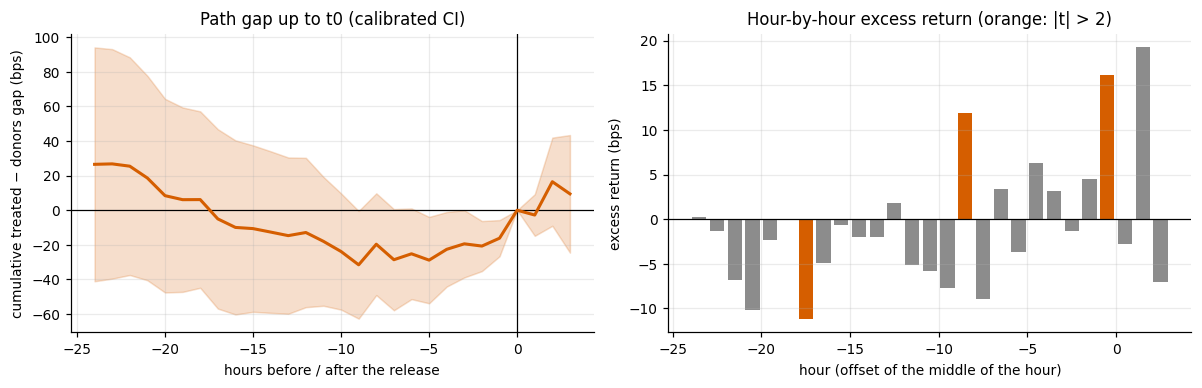

,donors,n,median_donors,gap_60_bps,t,max_abs_t,p_maxt
0,±30 days,88,12,-16.718,-3.838,4.089,0.002
1,±90 days,113,33,-15.993,-4.686,4.762,0.001
2,±180 days (reference),113,66,-16.164,-4.803,4.897,0.001
3,±365 days,113,131,-15.707,-4.774,4.863,0.001
4,same weekday,40,23,-23.281,-3.488,4.191,0.002


-> If the gap stays negative (BTC rises before t0) and significant whatever the pool, the drift is not an artefact of the donor definition.


In [16]:
# 9.3 Hour-by-hour profile of the drift (from -24 h to +3 h) + robustness to the donor definition
es0 = ES["08:30"]
OFF = np.arange(-1440, 181, 60)                                   # offsets in minutes, one-hour steps
gap_h, pool_path, okp = hourly_profile(es0, "08:30", OFF)
okh = np.isfinite(gap_h).all(1) & VALID[:len(es0.ev)]
gh = gap_h[okh]; mh = gh.mean(0); se_n = gh.std(0, ddof=1) / np.sqrt(len(gh))
pool0 = es0.pools["08:30"]
null = placebo_profile(pool0["dates"], pool_path, 180, int(okh.sum()), n_draw=400, seed=SEED)
se_c = null.std(0)                                                # std. dev. under H0 (includes donor sharing)
inc = np.diff(mh); inc_se = np.diff(null, axis=1).std(0)         # excess return of each hour = change in the cumulative gap
HP = pd.DataFrame({"offset_h": OFF / 60, "gap_bps": mh, "se_naive": se_n, "se_calibrated": se_c,
                   "t_calibrated": mh / se_c, "p_placebo": [(1 + (np.abs(null[:, k]) >= abs(mh[k])).sum()) / (1 + len(null)) for k in range(len(OFF))]})
display(HP.round(3).iloc[::2])
hr = pd.DataFrame({"hour_start_h": OFF[:-1] / 60, "excess_return_bps": inc[:len(OFF) - 1], "se_calibrated": inc_se})
hr["t"] = hr.excess_return_bps / hr.se_calibrated
print("Excess return per hour (treated − donors), the 6 strongest hours:")
print(hr.reindex(hr.t.abs().sort_values(ascending=False).index).head(6).round(2).to_string(index=False))
pd.DataFrame({"offset_h": HP.offset_h, "gap_bps": HP.gap_bps, "ci_low": HP.gap_bps - 1.96 * HP.se_calibrated, "ci_high": HP.gap_bps + 1.96 * HP.se_calibrated,
              "ret_bps": np.r_[hr.excess_return_bps, np.nan], "ret_se": np.r_[hr.se_calibrated, np.nan], "ret_t": np.r_[hr.t, np.nan]}).round(3).to_csv(OUT/"hourly_profile.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axs[0]; ax.axhline(0, color="k", lw=.8); ax.axvline(0, color="k", lw=.8)
ax.fill_between(OFF / 60, mh - 1.96 * se_c, mh + 1.96 * se_c, color=C_T, alpha=.2); ax.plot(OFF / 60, mh, color=C_T, lw=2)
ax.set_xlabel("hours before / after the release"); ax.set_ylabel("cumulative treated − donors gap (bps)"); ax.set_title("Path gap up to t0 (calibrated CI)")
ax = axs[1]; ax.axhline(0, color="k", lw=.8); ax.bar(hr.hour_start_h + .5, hr.excess_return_bps, width=.8, color=np.where(hr.t.abs() > 2, C_T, C_G))
ax.set_xlabel("hour (offset of the middle of the hour)"); ax.set_ylabel("excess return (bps)"); ax.set_title("Hour-by-hour excess return (orange: |t| > 2)")
banner(axs[0]); plt.tight_layout(); plt.savefig(FIG/"hourly_profile.png"); plt.show()

# 9.4 Robustness to the donor definition: does the gap at -60 min depend on the pool?
k60 = np.where(TAUS == -60)[0][0]; base = ev[ev.time_ny == "08:30"].reset_index(drop=True); rows = []
for lab, W in [("±30 days", 30), ("±90 days", 90), ("±180 days (reference)", 180), ("±365 days", 365)]:
    es = es0 if W == 180 else EventStudy(P_, base, EXCL, donor_window_days=W)
    r = es.res["did"] if W == 180 else es.did()
    ok = np.isfinite(r["gap"]).all(1); g = r["gap"][ok]; pt = pretrend_test(g, n_flip=1000)
    rows.append(dict(donors=lab, n=int(ok.sum()), median_donors=int(np.median(r["nj"][ok])), gap_60_bps=g[:, k60].mean(),
                     t=g[:, k60].mean() / (g[:, k60].std(ddof=1) / np.sqrt(len(g))), max_abs_t=pt["max_abs_t"], p_maxt=pt["p_maxt_signflip"]))
# same weekday only (neutralises any weekday effect)
dow = pd.to_datetime(pool0["dates"]).dayofweek.to_numpy(); gg = np.full((len(es0.ev), len(TAUS)), np.nan)
for i in range(len(es0.ev)):
    if not es0.ev.ok.iloc[i]: continue
    dj, _ = es0.donors(i); dj = dj[dow[dj] == pd.Timestamp(es0.ev.date_ny.iloc[i]).dayofweek]
    if len(dj) >= 5: gg[i] = es0.ev_w["path"][i] - pool0["path"][dj].mean(0)
ok = np.isfinite(gg).all(1); g = gg[ok]; pt = pretrend_test(g, n_flip=1000)
rows.append(dict(donors="same weekday", n=int(ok.sum()), median_donors=int(np.median([(dow[es0.donors(i)[0]] == pd.Timestamp(es0.ev.date_ny.iloc[i]).dayofweek).sum() for i in np.where(ok)[0]])),
                 gap_60_bps=g[:, k60].mean(), t=g[:, k60].mean() / (g[:, k60].std(ddof=1) / np.sqrt(len(g))), max_abs_t=pt["max_abs_t"], p_maxt=pt["p_maxt_signflip"]))
ROB = pd.DataFrame(rows); display(ROB.round(3)); ROB.round(3).to_csv(OUT/"donor_robustness.csv", index=False)
print("-> If the gap stays negative (BTC rises before t0) and significant whatever the pool, the drift is not an artefact of the donor definition.")

## 10. Identification critique
Each assumption is linked to the test that challenges it. Figures: 151 events (56 CPI, 57 NFP, 38 FOMC), 2022-01 to 2026-10; surprises available for 128 of them.

| # | Assumption | Verdict | Evidence / test |
|---|---|---|---|
| 1 | **Exogenous calendar.** Dates are published in advance, hence independent of BTC. | Plausible for the **date**. Less so for the **content**: the surprise depends on the state of the economy, which is linked to the BTC regime. | Local donors (±180 days) absorb the regime. Sub-samples by period in §7.2. |
| 2 | **Parallel trends (DiD).** Without a release, treated and donor days would have moved alike before t0. | **Rejected.** The (treated − donors) gap is about −20 bps at −60 min, i.e. BTC rises before the announcement. | Max-\|t\| = 5.6; placebo-calibrated p = 0.002 (§5.7); confirmed separately at 08:30 (113 events: −16 bps at −60 min, p = 0.003) and at 14:00 (38 FOMC: −30 bps, p = 0.010); robust to winsorisation, same-weekday donors and pool size (§5.5, §9.4). |
| 3 | **No anticipation.** BTC does not react before the announcement. | **Apparently violated**, cause not demonstrated. The drift only appears at the true clock (shifted clocks are null after calibration) and is concentrated in the last hour (§9.3). | Same sign every year, stronger for CPI. Reading: positioning or information circulating before the release, or a calendar effect. Not to be presented as a fact. |
| 4 | **SUTVA / no interference.** Each event is independent. | Partly violated: neighbouring events share donor days. | Placebo-calibrated standard errors: SE × 1.2 to 1.6 vs naive (§5.7). The HC1 SEs of §7 do **not** correct for this sharing: the Fisher permutation is the reference. |
| 5 | **No concurrent news.** Nothing else happens at the release time. | Not verifiable: Fed speakers, crypto news, ETF flows. | Other 08:30 / 14:00 releases (FOMC minutes) and Thursdays at 08:30 are excluded. Possible bias in both directions. |
| 6 | **Stable regime.** The same effect over 2022-2026. | **Heterogeneous.** Vol ×2.4 on average (151 events; the naive after-only comparison overstates the FOMC effect because those days are already more volatile before 14:00, §5.0); share of significant events 51% before the spot ETFs versus 34% after. Directional slope at 5 min: −98 bps/σ in 2022, −32 excluding 2022. | §9.2 and §7.2. **Exploratory**: sub-samples not pre-registered. |
| 7 | **Counterfactual quality (synthetic day).** The donor mix reproduces BTC before t0. | Good but imperfect fit: median pre RMSPE 0.46 (ridge) and 0.65 (classical). | §6 and §6.2. Both methods agree (41% vs 44% of events at p < 0.05, correlation 0.99). Classical version: only ~5 effective donors. |
| 8 | **No information leakage (SC).** | Satisfied. | λ tuned on placebo days, never on treated days. |
| 9 | **Surprise measurement.** | Imperfect. NFP: Investing.com consensus (57/57). CPI: *core* m/m only, 35% zero surprises (rounding to 0.1 pt), 55/56 covered. FOMC: Bauer-Swanson surprise, 16/38 decisions (2022-2023). | Measurement error → likely attenuation bias (slopes rather underestimated). The z-score is computed by type: slopes are **not** comparable in level across types. |
| 10 | **External validity.** | Limited: 2-hour window, one venue (Binance BTCUSDT spot), one asset, FOMC surprise limited to 2022-2023. | No test. Long-run effects not studied. |

**Falsification (§9).** Away from the true clock, the volatility effect disappears: DiD vol = 0.04 (t = 0.7), 0.02 (t = 0.5) and −0.03 (t = −0.6) for clocks shifted by −12 h, −6 h and +6 h, versus 0.97 (t = 16.1) at the true clock (08:30 events). For the direction: (a) **Fisher permutation** (p_perm < 0.001 for the pooled slope); (b) **stability of the sign**: negative slope in 20 sub-samples out of 20 (§7.2); (c) **estimators robust** to extreme values (§7.3): winsorised OLS −49 bps/σ, Theil-Sen −49, Spearman correlation −0.58 at 5 min; (d) **placebo on the pre-period** (§7.4): the surprise, unknown before t0, should not explain the path before the announcement. Slope of −8.5 bps/σ at −60 min (p = 0.04) and −5.8 at −30 min (p = 0.13), about 8 times smaller than the post effect. The sign is the opposite of an information leak (BTC rises slightly more before hawkish surprises): a weak signal, reported, that does not call the post effect into question.

**Power (§8).** With the 128 events that have a surprise, the minimal detectable directional effect is ≈ 28 bps per σ at 5 min and 39 bps at 30 min. The observed slopes (−65 to −80 bps/σ pooled) are about twice that threshold; the NFP slope alone (−26 to −29, 57 events) is below the pooled threshold: its significant result at 5 min relies on the lower variance of NFP reactions.

**What is identified.** (i) A **volatility** effect: robust to falsification and to both versions of the synthetic control. (ii) A **negative directional** effect (a surprise above expectations, i.e. more hawkish, lowers BTC), stable in sign, with the caveats below.

**Caveats on the directional effect.** 4 horizons tested (Bonferroni ×4: 18 sub-samples out of 20 remain significant at 5%, but NFP at 30 min and "excluding 2022" at 30 min move to p ≈ 0.06-0.09); pooled slope driven by core CPI and FOMC (z-scores not comparable); effect much weaker since 2023; no correction for donor sharing in the HC1 SEs. **Not identified**: the cause of the pre-release drift and the price effect beyond one hour.

**Next improvements.** Month-block bootstrap; headline CPI; FOMC surprises 2024-2026 (no free source); "honest DiD" (Rambachan-Roth), outside the course and optional, to bound the effect despite the violated parallel trends.

## 11. Recommendation (one page)
> **Decision**: *should a desk or an investor treat US macro releases (CPI, NFP, FOMC) as a risk trigger on BTC, and can it draw a directional signal from them?*
>
> **Answer: yes for risk; for direction, the sign is stable but the magnitude is uncertain, so it is useful for risk management, not yet for a strategy.**
>
> **1. Causal findings.**
> - *Volatility.* The 30 minutes after a release have a realised volatility **×2.4** (DiD over the 151 events, t = 17; NFP ×2.5, CPI ×2.7, FOMC ×1.9) relative to the same minutes on a day without a release; 41-44% of events are significant against placebos (5% expected); the effect disappears when the clock is shifted.
> - *Direction.* Measured with the synthetic day, the reaction follows the surprise: **−65 bps per σ at 5 min, −80 at 30 min** (128 events, permutation p < 0.001). A more hawkish release than expected (higher NFP or core CPI, hawkish monetary policy surprise) makes BTC **fall**. Negative sign in 20 sub-samples out of 20; stronger in 2022 (−98) than afterwards (−32 excluding 2022).
> - *Before the release.* BTC rises by about 20 bps in the 2 hours before (mostly in the last hour). Parallel trends are rejected (p = 0.002): the equal-weight DiD is not credible for the signed effect, hence the synthetic day.
>
> **2. What we can / cannot claim.**
> - *Can claim*: releases strongly increase short-term volatility; the short-term reaction goes in the direction "good macro news = bad news for BTC".
> - *Cannot claim*: a precise magnitude (z-scores not comparable across types, core CPI only, FOMC surprises for 16 decisions); that the effect is stable (it fell markedly after 2022); that the pre-release drift can be traded or is due to anticipation (cause not demonstrated).
>
> **3. Operational implications.** Reduce size or leverage on BTC before 08:30 New York (and 14:00 on FOMC days), widen stops and risk limits over the first 30 minutes, avoid executing large orders in that window. On direction: a number above consensus justifies hedging a long position rather than opening a short; no systematic directional strategy without out-of-sample validation and execution costs.
>
> **4. Follow-up.** (a) Validate out of sample on the next 2 to 3 releases; (b) headline CPI and FOMC surprises 2024-2026; (c) a control asset (ETH, gold) to see whether the pre-release drift is specific to BTC; (d) month-block bootstrap for the standard errors.